# Restaurant Dataset - Customer Preference Analysis

### Level 3 - Task 2

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_csv("../Engineered_Dataset.csv")

df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes,Restaurant Name Length,Address Length,Cuisine Count,Has Table Booking,Has Online Delivery,Rating Category,Cost Per Vote,Has Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314,16,71,3,1,0,Excellent,3.492063,1
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591,16,67,1,1,0,Good,2.027027,1
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270,22,56,4,1,0,Good,14.760148,1
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365,4,70,2,0,0,Excellent,4.098361,1
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229,11,64,2,1,0,Excellent,6.521739,1


In [4]:
cuisine_df = df.copy()

cuisine_df["Cuisines"] = cuisine_df["Cuisines"].fillna("Unknown")

cuisine_df = cuisine_df.assign(
    Cuisine=cuisine_df["Cuisines"].str.split(", ")
).explode("Cuisine")

cuisine_df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes,Restaurant Name Length,Address Length,Cuisine Count,Has Table Booking,Has Online Delivery,Rating Category,Cost Per Vote,Has Votes,Cuisine
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314,16,71,3,1,0,Excellent,3.492063,1,French
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314,16,71,3,1,0,Excellent,3.492063,1,Japanese
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314,16,71,3,1,0,Excellent,3.492063,1,Desserts
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591,16,67,1,1,0,Good,2.027027,1,Japanese
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270,22,56,4,1,0,Good,14.760148,1,Seafood


### Cuisine vs Rating

In [6]:
# Average Rating by Cuisine
cuisine_rating = (
    cuisine_df.groupby("Cuisine")["Aggregate rating"]
    .mean()
    .sort_values(ascending=False)
)

cuisine_rating.head(15)

Cuisine
Sunda            4.900000
B�_rek           4.700000
Taiwanese        4.650000
Ramen            4.500000
Dim Sum          4.466667
Hawaiian         4.412500
Bubble Tea       4.400000
D�_ner           4.400000
Curry            4.400000
Kebab            4.380000
Izgara           4.350000
Filipino         4.340000
Scottish         4.333333
South African    4.333333
Turkish Pizza    4.325000
Name: Aggregate rating, dtype: float64

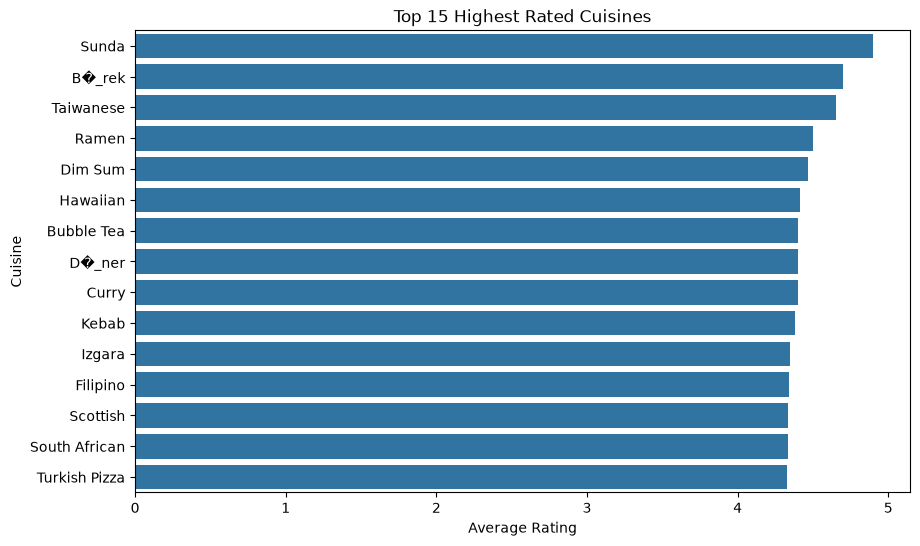

In [7]:
#plotting the average rating by cuisine
plt.figure(figsize=(10,6))

sns.barplot(
    x=cuisine_rating.head(15).values,
    y=cuisine_rating.head(15).index
)

plt.title("Top 15 Highest Rated Cuisines")
plt.xlabel("Average Rating")
plt.ylabel("Cuisine")

plt.show()

### Cuisine vs Votes

In [ ]:
# Total Votes by Cuisine
cuisine_votes = (
    cuisine_df.groupby("Cuisine")["Votes"]
    .sum()
    .sort_values(ascending=False)
)

cuisine_votes.head(15)

Cuisine
North Indian     598707
Chinese          364351
Italian          329265
Continental      288255
Fast Food        184058
American         183117
Cafe             177568
Mughlai          151946
Desserts         105889
Asian            104303
European         103309
South Indian      80962
Mediterranean     80538
Pizza             78179
Burger            76747
Name: Votes, dtype: int64

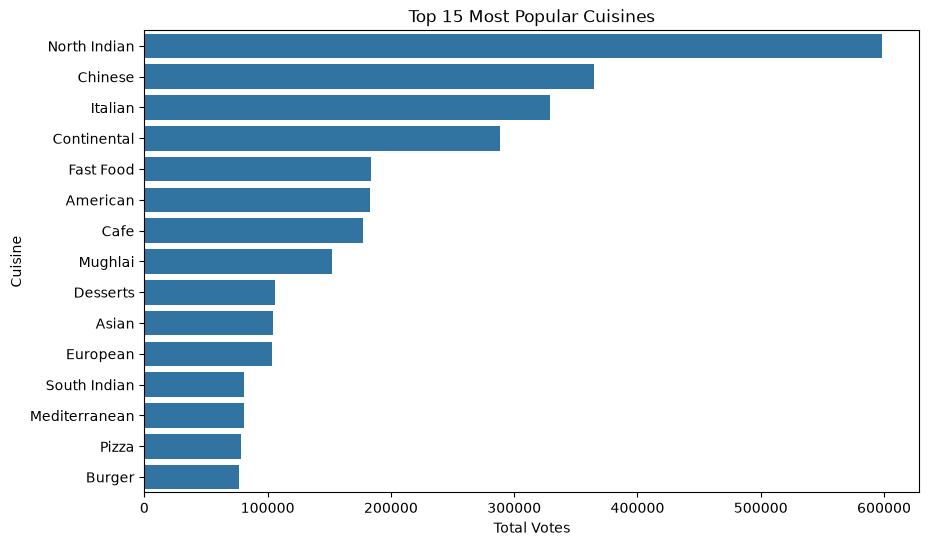

In [9]:
# Plotting the total votes by cuisine
plt.figure(figsize=(10,6))

sns.barplot(
    x=cuisine_votes.head(15).values,
    y=cuisine_votes.head(15).index
)

plt.title("Top 15 Most Popular Cuisines")
plt.xlabel("Total Votes")
plt.ylabel("Cuisine")

plt.show()

In [10]:
# Restaurant Count by Cuisine
cuisine_count = (
    cuisine_df["Cuisine"]
    .value_counts()
)

cuisine_count.head(15)

Cuisine
North Indian    3969
Chinese         2735
Fast Food       1986
Mughlai          995
Italian          764
Bakery           745
Continental      736
Cafe             703
Desserts         653
South Indian     636
Street Food      562
American         390
Pizza            381
Mithai           380
Burger           251
Name: count, dtype: int64

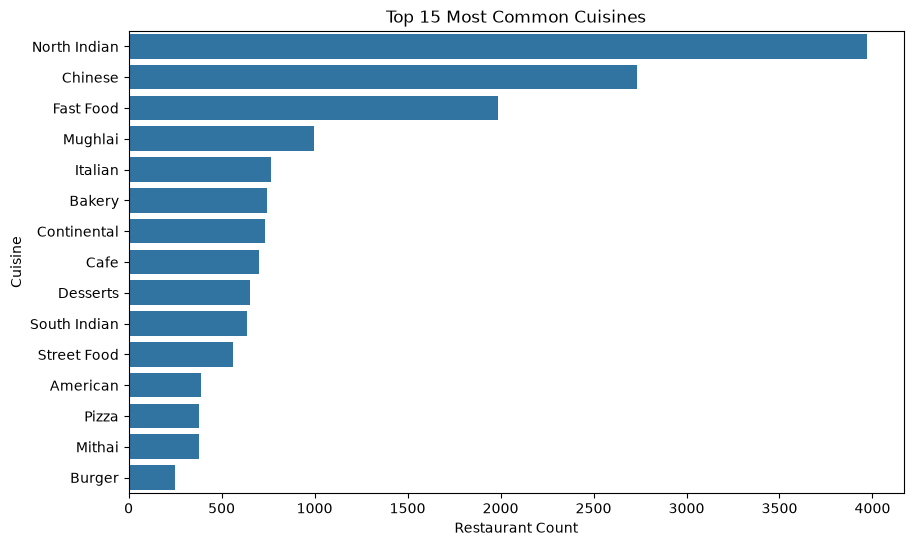

In [11]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=cuisine_count.head(15).values,
    y=cuisine_count.head(15).index
)

plt.title("Top 15 Most Common Cuisines")
plt.xlabel("Restaurant Count")

plt.show()

### Highly Rated Cuisines 

In [14]:
min_restaurants = 10

qualified = cuisine_df.groupby("Cuisine").filter(
    lambda x: len(x) >= min_restaurants
)

qualified_rating = (
    qualified.groupby("Cuisine")["Aggregate rating"]
    .mean()
    .sort_values(ascending=False)
)

qualified_rating.head(15)

Cuisine
Kebab             4.380000
Filipino          4.340000
Indonesian        4.285714
Modern Indian     4.281250
International     4.247619
Cajun             4.200000
Western           4.140000
Tapas             4.131579
Southern          4.129167
British           4.112500
Spanish           4.081250
Vegetarian        4.073913
Sandwich          4.066038
Latin American    4.063636
Grill             4.057143
Name: Aggregate rating, dtype: float64

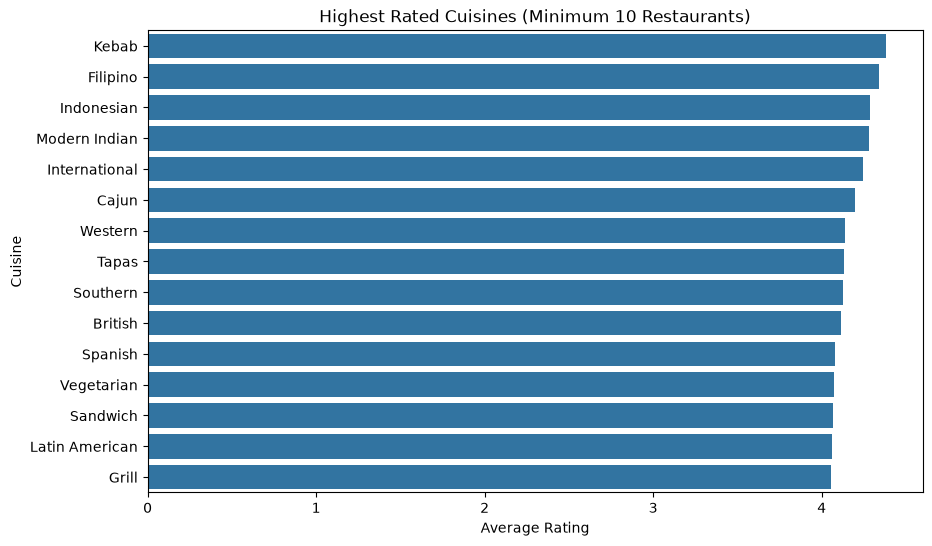

In [15]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=qualified_rating.head(15).values,
    y=qualified_rating.head(15).index
)

plt.title("Highest Rated Cuisines (Minimum 10 Restaurants)")
plt.xlabel("Average Rating")

plt.show()

### Rating Distribution by Cuisine

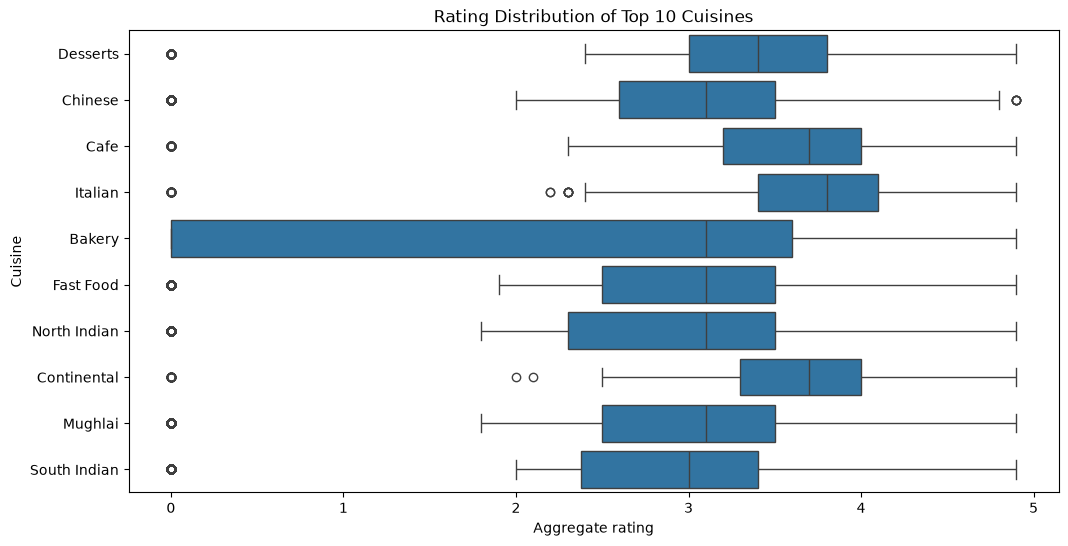

In [16]:
top_cuisines = cuisine_count.head(10).index

plt.figure(figsize=(12,6))

sns.boxplot(
    data=cuisine_df[cuisine_df["Cuisine"].isin(top_cuisines)],
    x="Aggregate rating",
    y="Cuisine"
)

plt.title("Rating Distribution of Top 10 Cuisines")

plt.show()

### Correlation between Rating and Votes

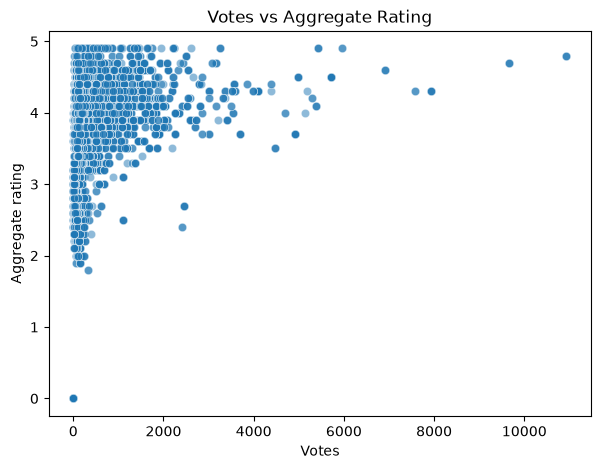

In [17]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    data=cuisine_df,
    x="Votes",
    y="Aggregate rating",
    alpha=0.5
)

plt.title("Votes vs Aggregate Rating")

plt.show()

### Key Customer Insights

In [ ]:
print("Highest Rated Cuisine:")
print(qualified_rating.idxmax())

print()

print("Most Popular Cuisine:")
print(cuisine_votes.idxmax())

print()

print("Most Common Cuisine:")
print(cuisine_count.idxmax())

## Customer Preference Insights

- Some cuisines consistently receive higher ratings than others.
- Popular cuisines are not always the highest rated.
- A small number of cuisines dominate the restaurant market.
- Restaurants serving highly preferred cuisines tend to receive more customer engagement.
- Votes and ratings show a positive relationship, although exceptions exist.